In [24]:
from pathlib import Path as P
import pandas as pd
import numpy as np
import matplotlib

In [25]:
# Adding the clean_games.csv  file cleaned in pervious stage
try :
    dir = P(__file__).resolve().parent
except NameError :                      # using try expect if anyone run this into simple 
    dir = P.cwd()
file_path = dir / "data"
df = pd.read_csv(file_path / "clean_games.csv", parse_dates=["Release Date"]) # use prase_date= inside read so no need to tell it that release date column is the date time object

In [26]:
(df.isna().mean()*100).sort_values(ascending=False)
df["Units(m)"].notna().sum()


np.int64(11956)

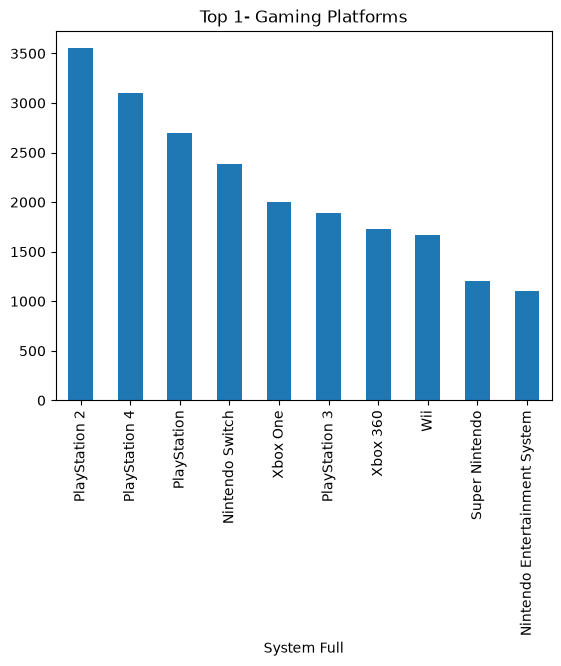

In [28]:
df_sort_by_sales = df.sort_values(by="Units(m)",ascending=False)
df_top10_pub = df["System Full"].value_counts().head(10).plot(kind="bar",title="Top 1- Gaming Platforms")

In [ ]:
df_total_sales_per_platform = df.groupby("System Full")["Units(m)"].sum().sort_values(ascending=False).head(10) #Totall sales per platform (Top 10 only) slower and keep NaN values also
df_total_sales_per_publisher = df.groupby("Publisher")["Units(m)"].sum().nlargest(10)    #Totall sales per Publisher (Top 10 only) Faster and drop NaN values 
print(df_total_sales_per_platform,
      df_total_sales_per_publisher)

System Full
PlayStation 2                    1256.22
Xbox 360                          974.22
PlayStation 3                     964.11
Wii                               896.84
PlayStation 4                     849.06
PlayStation                       714.00
Nintendo Switch                   664.10
Xbox One                          309.06
Nintendo Entertainment System     263.14
Xbox                              261.35
Name: Units(m), dtype: float64 Publisher
Nintendo                       1529.92
Activision                      644.76
Electronic Arts                 526.30
Sony Computer Entertainment     520.22
EA Sports                       463.50
Ubisoft                         404.37
Rockstar Games                  235.44
THQ                             230.07
Sega                            225.56
Capcom                          210.97
Name: Units(m), dtype: float64


In [ ]:
# Only the top 10 best selling games 
df_top10_games = df.nlargest(10,"Units(m)")[["Publisher","Game Name","System Full"]]
print(df_top10_games)

KeyError: "None of [Index(['Publisher', 'Game Name', 'System Full'], dtype='str')] are in the [index]"